# K-means: Grouping Community Areas by How They Use Rideshare

Goal: group Chicago's 77 community areas by their rideshare usage profile (issue #12).

Data: the cleaned trips from 2023 onward (after the COVID break), summarized per pickup community area by `src/mining/kmeans_areas.py` on Dataproc. Each area gets 12 features: the share of its trips in five time bands, the weekend share, the share going downtown, to the airports or staying in the same area, average distance, average fare, and trips per km² (log scale). Features are standardized before clustering, and K-means is run for k = 2 to 10.

In [1]:
from pathlib import Path
import glob
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Folder with the Dataproc outputs (downloaded with gcloud storage cp -r).
# Use "mining_test" for the 200k-sample test run, "mining" for the full-data run.
RESULTS = ROOT / "results" / "mining"
FIGS = ROOT / "docs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

def read_spark_csv(name):
    """Spark writes each output as a folder with one part-*.csv file inside."""
    files = glob.glob(str(RESULTS / name / "part-*.csv"))
    assert files, f"no CSV found in {RESULTS / name}"
    return pd.read_csv(files[0])

scores = read_spark_csv("kmeans_scores").sort_values("k")
clusters = read_spark_csv("kmeans_clusters")
profile = read_spark_csv("area_profile")
profile["name"] = profile["name"].replace({"Ohare": "O'Hare"})
print(len(profile), "areas,", len(scores), "values of k")
scores

77 areas, 9 values of k


,k,silhouette,cost
0,2,0.481534,710.501365
1,3,0.452589,567.424414
2,4,0.275854,507.328158
3,5,0.321568,462.725900
4,6,0.293737,398.452773
5,7,0.275184,431.840683
6,8,0.275909,335.725886
7,9,0.283758,319.319274
8,10,0.137774,353.786896


## Choosing k: elbow and silhouette

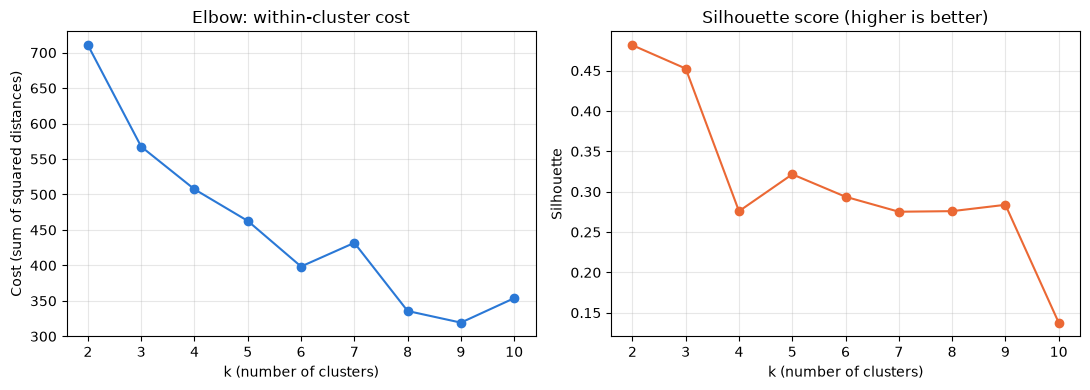

Chosen k: 3 | silhouette: 0.453


In [2]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(scores["k"], scores["cost"], marker="o", color="#2a78d6")
a1.set(title="Elbow: within-cluster cost", xlabel="k (number of clusters)", ylabel="Cost (sum of squared distances)")
a2.plot(scores["k"], scores["silhouette"], marker="o", color="#eb6834")
a2.set(title="Silhouette score (higher is better)", xlabel="k (number of clusters)", ylabel="Silhouette")
for a in (a1, a2):
    a.set_xticks(scores["k"]); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS / "kmeans_choose_k.png", dpi=150, bbox_inches="tight")
plt.show()

# k = 2 usually just splits downtown from everything else, so pick the best silhouette from k = 3 to 8.
# If the elbow chart suggests a different k, set K by hand here and say why in the text below.
K = int(scores[scores["k"].between(3, 8)].sort_values("silhouette", ascending=False)["k"].iloc[0])
print("Chosen k:", K, "| silhouette:", round(scores.set_index("k").loc[K, "silhouette"], 3))

TODO (Harsh): 2–3 sentences. Which k did you pick and why? Use the silhouette value for that k and what the elbow chart shows. Mention that k = 2 only separates downtown from the rest, if that is what the clusters show.

## What each cluster looks like

In [3]:
FEATURES = ["share_night", "share_morning", "share_midday", "share_evening", "share_late",
            "share_weekend", "share_to_downtown", "share_to_airport", "share_same_area",
            "avg_miles", "avg_fare", "log_trips_per_km2"]
assign = clusters[clusters["k"] == K][["area", "cluster"]]
df = profile.merge(assign, on="area")

summary = df.groupby("cluster").agg(
    areas=("area", "count"),
    trips=("trips", "sum"),
    **{f: (f, "mean") for f in FEATURES},
    dist_to_L_km=("dist_to_L_km", "mean"))
summary["example_areas"] = df.sort_values("trips", ascending=False).groupby("cluster")["name"] \
    .apply(lambda s: ", ".join(s.head(4)))
summary.round(3)

,areas,trips,share_night,share_morning,share_midday,share_evening,share_late,share_weekend,share_to_downtown,share_to_airport,share_same_area,avg_miles,avg_fare,log_trips_per_km2,dist_to_L_km,example_areas
cluster,,,,,,,,,,,,,,,,
0,55,56975,0.100,0.264,0.321,0.190,0.125,0.020,0.129,0.054,0.122,6.683,12.854,2.081,2.605,"Austin, Rogers Park, West Ridge, South Shore"
1,20,99686,0.096,0.193,0.301,0.239,0.172,0.030,0.291,0.091,0.108,5.976,13.696,2.687,0.733,"Near North Side, Near West Side, Loop, Lake View"
2,2,19916,0.094,0.119,0.318,0.187,0.281,0.049,0.533,0.076,0.067,15.214,29.960,2.614,1.670,"O'Hare, Garfield Ridge"


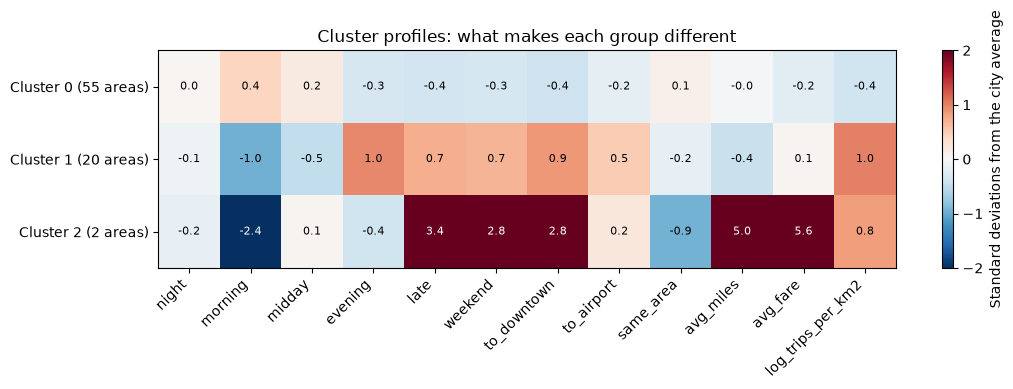

In [10]:
# How far each cluster is from the city average on each feature (in standard deviations)
z = (df[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()
z["cluster"] = df["cluster"]
centers = z.groupby("cluster")[FEATURES].mean()

fig, ax = plt.subplots(figsize=(11, 0.6 * K + 2))
im = ax.imshow(centers, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(FEATURES)), [f.replace("share_", "") for f in FEATURES], rotation=45, ha="right")
ax.set_yticks(range(K), [f"Cluster {c} ({(df.cluster == c).sum()} areas)" for c in centers.index])
for i in range(K):
    for j in range(len(FEATURES)):
        v = centers.iloc[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 1.2 else "black")
fig.colorbar(im, ax=ax, label="Standard deviations from the city average")
ax.set_title("Cluster profiles: what makes each group different")
plt.tight_layout()
plt.savefig(FIGS / "kmeans_cluster_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

TODO (Harsh): one short paragraph per cluster. Give each cluster a plain name (for example "downtown and nightlife", "airport", "outer residential"), then say what makes it different, using the numbers in the table and the colors in the chart.

## Map of the clusters

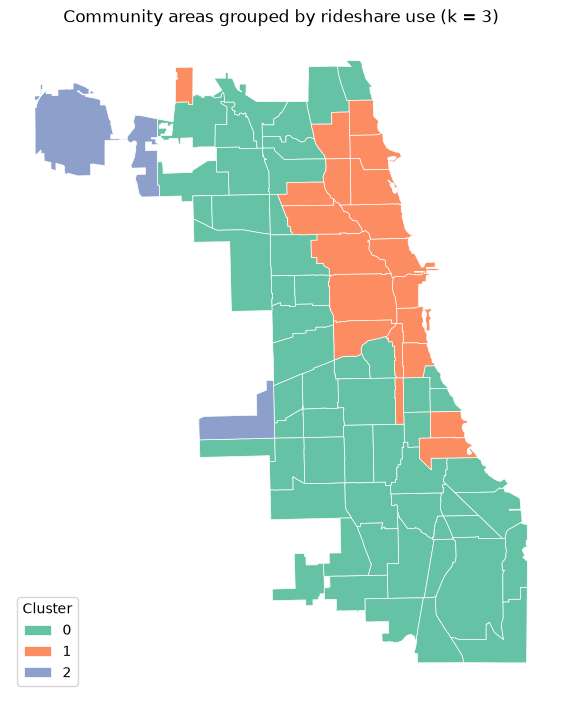

In [4]:
areas = gpd.read_file(ROOT / "data" / "raw" / "supporting" / "community_areas.geojson")
num_col = [c for c in areas.columns if c.lower().startswith("area_num")][0]
areas["area"] = areas[num_col].astype(float).astype(int)
m = areas.merge(df[["area", "name", "cluster", "dist_to_L_km"]], on="area")
m["cluster"] = m["cluster"].astype(str)

ax = m.plot(column="cluster", categorical=True, cmap="Set2", legend=True, figsize=(7, 9),
            edgecolor="white", linewidth=0.5,
            legend_kwds={"title": "Cluster", "loc": "lower left"})
ax.set_axis_off()
ax.set_title(f"Community areas grouped by rideshare use (k = {K})")
plt.savefig(FIGS / "kmeans_clusters_map.png", dpi=150, bbox_inches="tight")
plt.show()

TODO (Harsh): 2–3 sentences. Where is each cluster on the map? Do the clusters follow the 'L' lines from Yousuf's map (`docs/figures/cta_distance_map.png`)?

## Save the cluster for each area

In [5]:
out = df[["area", "name", "cluster", "trips", "dist_to_L_km"]].sort_values(["cluster", "area"])
out.to_csv(ROOT / "results" / "kmeans_area_clusters.csv", index=False)
print("saved", len(out), "areas to results/kmeans_area_clusters.csv")
out.groupby("cluster")["name"].apply(lambda s: ", ".join(s)).to_frame("areas")

saved 77 areas to results/kmeans_area_clusters.csv


,areas
cluster,
0,"Rogers Park, West Ridge, Norwood Park, Jeffers..."
1,"Uptown, Lincoln Square, North Center, Lake Vie..."
2,"Garfield Ridge, O'Hare"


## What this means for the project

TODO (Harsh): 2–3 bullets. Which cluster(s) look like possible transit gaps (lots of rideshare use, far from the 'L')? How will the clusters be used in the transit-gap score and the demand model in Sprint 3?